In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import seaborn

from datasets import load_dataset
from pathlib import Path


In [2]:
dataset = "TimKoornstra/financial-tweets-sentiment"

print("---Loading Dataset---")
ds = load_dataset(dataset, split="train")
df = ds.to_pandas()

---Loading Dataset---


In [3]:
# Tải file raw ra data
ROOT = Path.cwd()

raw_output_dir = ROOT / ".." / "data" / "raw" / "text_b"
raw_output_dir.mkdir(parents=True, exist_ok=True)

raw_output_file = raw_output_dir / "financial_tweets_sentiment_raw.csv"
df.to_csv(raw_output_file)

In [4]:
print(df.info())
print("\nPhân bố nhãn:\n", df["sentiment"].value_counts())
print(df.head(5))

<class 'pandas.DataFrame'>
RangeIndex: 38091 entries, 0 to 38090
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   tweet      38091 non-null  str  
 1   sentiment  38091 non-null  int64
 2   url        38091 non-null  str  
dtypes: int64(1), str(2)
memory usage: 6.8 MB
None

Phân bố nhãn:
 sentiment
1    17368
0    12181
2     8542
Name: count, dtype: int64
                                               tweet  sentiment  \
0  $BYND - JPMorgan reels in expectations on Beyo...          2   
1  $CCL $RCL - Nomura points to bookings weakness...          2   
2  $CX - Cemex cut at Credit Suisse, J.P. Morgan ...          2   
3  $ESS: BTIG Research cuts to Neutral https://t....          2   
4  $FNKO - Funko slides after Piper Jaffray PT cu...          2   

                                                 url  
0  https://huggingface.co/datasets/zeroshot/twitt...  
1  https://huggingface.co/datasets/zeroshot/twitt...  
2  https:

In [5]:
# LABEL cho giá trị
# 0: Neutral (Trung tính)
# 1: Bullish (Tích cực / Kỳ vọng tăng)
# 2: Bearish (Tiêu cực / Kỳ vọng giảm)
label_map = {
    0: "Neutral",
    1: "Bullish",
    2: "Bearish"
}

df["label"] = df["sentiment"].map(label_map)

## 1. Text EDA

In [80]:
def plot_text_eda(text: pd.Series, label: pd.Series):
    text_len = len(text)
    label_len = len(label)
    if text_len != label_len:
        print(f"Invalid Length: {text_len} != {label_len}")
        return
    
    text_length = pd.Series(text.str.len())
    
    char_counts = pd.Series(text.str.replace(r'\s+', '', regex=True).str.len())
    word_counts = pd.Series(text.str.findall(r'\b\w+\b').str.len())

    fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize=(14,5))
    
    for i, l in enumerate(label.unique()):
        mask = label == l

        axes[i].hist(text_length[mask],
                    bins=35, range=(0, 350), 
                    density=True, 
                    color=plt.cm.tab10.colors[i])
        axes[i].set_title(f"Label: {l}")
        axes[i].set_xlabel("Text Length")
        axes[i].set_ylabel("Frequency")


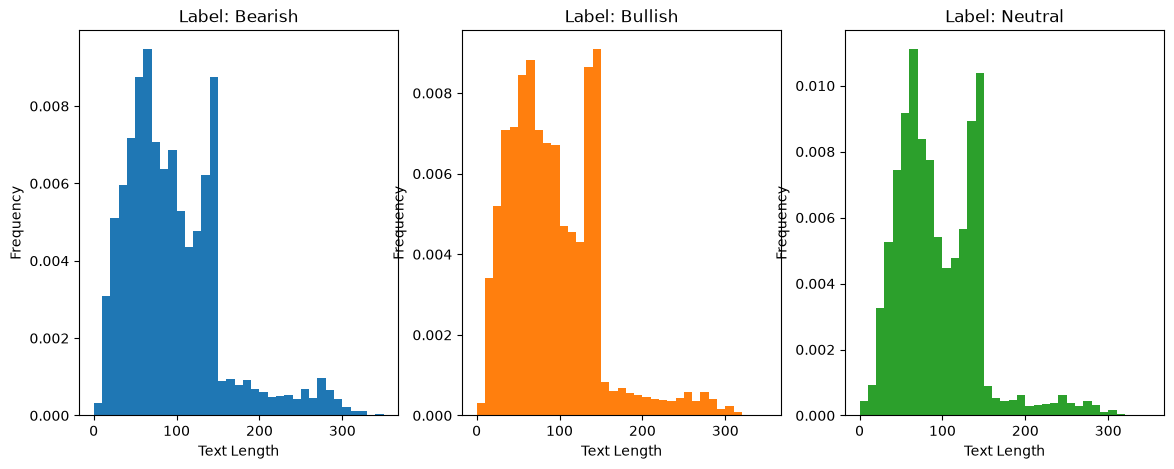

In [81]:
plot_text_eda(df["tweet"], df['label'])